# Lending Club

#### Pregunta del Negocio:

¿Podemos identificar los préstamos con mayor riesgo de incumplimiento utilizando únicamente la información disponible al momento de evaluar o conceder el crédito?

### Objetivo técnico

Comparar cuatro algoritmos de clasificación y determinar cuál ofrece el equilibrio más útil entre detección de incumplimientos, falsas alarmas y confiabilidad de las probabilidades.

## Codigo

In [1]:
### Librerias
import pandas as pd
import numpy as np
import os
import gc
import csv

In [2]:
#Lectura de Datost
os.getcwd()

'/home/marco-carrillo/Descargas/Repaso/Repositorio/Lending Club'

In [3]:
ruta = "accepted_2007_to_2018Q4.csv"

In [4]:
print(f"Tamaño: {os.path.getsize(ruta) / 1024**3:.2f} GB")

Tamaño: 1.56 GB


El tamano del archivo es muy grande por lo que vamos a delimitarlo

In [5]:
with open(ruta, "r", encoding="utf-8-sig", newline="") as archivo:
    lector = csv.reader(archivo)
    columnas = next(lector)

In [6]:
for i, columna in enumerate(columnas, 1):
    print(f"{i:3}. {columna}")

  1. id
  2. member_id
  3. loan_amnt
  4. funded_amnt
  5. funded_amnt_inv
  6. term
  7. int_rate
  8. installment
  9. grade
 10. sub_grade
 11. emp_title
 12. emp_length
 13. home_ownership
 14. annual_inc
 15. verification_status
 16. issue_d
 17. loan_status
 18. pymnt_plan
 19. url
 20. desc
 21. purpose
 22. title
 23. zip_code
 24. addr_state
 25. dti
 26. delinq_2yrs
 27. earliest_cr_line
 28. fico_range_low
 29. fico_range_high
 30. inq_last_6mths
 31. mths_since_last_delinq
 32. mths_since_last_record
 33. open_acc
 34. pub_rec
 35. revol_bal
 36. revol_util
 37. total_acc
 38. initial_list_status
 39. out_prncp
 40. out_prncp_inv
 41. total_pymnt
 42. total_pymnt_inv
 43. total_rec_prncp
 44. total_rec_int
 45. total_rec_late_fee
 46. recoveries
 47. collection_recovery_fee
 48. last_pymnt_d
 49. last_pymnt_amnt
 50. next_pymnt_d
 51. last_credit_pull_d
 52. last_fico_range_high
 53. last_fico_range_low
 54. collections_12_mths_ex_med
 55. mths_since_last_major_derog
 56. 

Vamos a trabajar con un conjunto de columnas reducido, por ejemplo, onto del préstamo, plazo, ingresos, antigüedad laboral, endeudamiento, historial de morosidad y estado del préstamo. con el paso del analisis podremos ir cambiando de variables si así se considera necesario

## Extracción

In [7]:
from pathlib import Path

In [8]:
# Archivo original
ruta = Path("accepted_2007_to_2018Q4.csv")

# Archivo de salida
salida = Path("lendingclub_sample.csv")
salida.parent.mkdir(parents=True, exist_ok=True)

In [9]:
columnas = [
    "loan_amnt",
    "term",
    "emp_length",
    "home_ownership",
    "annual_inc",
    "verification_status",
    "issue_d",
    "loan_status",
    "purpose",
    "addr_state",
    "dti",
    "delinq_2yrs",
    "earliest_cr_line",
    "fico_range_low",
    "fico_range_high",
    "inq_last_6mths",
    "open_acc",
    "pub_rec",
    "revol_bal",
    "revol_util",
    "total_acc",
    "collections_12_mths_ex_med",
    "application_type",
    "acc_now_delinq",
    "tot_coll_amt",
    "tot_cur_bal",
    "mort_acc",
    "pub_rec_bankruptcies",
    "tax_liens",
]


In [10]:
# Muestreo reproducible por bloques
n_objetivo = 200_000
tam_bloque = 100_000
semilla = 42

In [11]:
partes = []
n_acumulado = 0

for bloque in pd.read_csv(
    ruta,
    usecols=columnas,
    chunksize=tam_bloque,
    low_memory=True
):
    # Reservar espacio proporcional al tamaño del bloque
    restante = n_objetivo - n_acumulado
    if restante <= 0:
        break

    n_tomar = min(len(bloque), restante)

    # Muestreo aleatorio dentro de cada bloque
    muestra = bloque.sample(
        n=n_tomar,
        random_state=semilla
    )

    partes.append(muestra)
    n_acumulado += len(muestra)

    print(f"Registros procesados para la muestra: {n_acumulado:,}")

Registros procesados para la muestra: 100,000
Registros procesados para la muestra: 200,000


In [12]:
df = pd.concat(partes, ignore_index=True)
df.to_csv(salida, index=False)

In [13]:
print(f"\nMuestra guardada en: {salida}")
print(f"Dimensiones: {df.shape}")
print("\nEstados del préstamo:")
print(df["loan_status"].value_counts(dropna=False))


Muestra guardada en: lendingclub_sample.csv
Dimensiones: (200000, 29)

Estados del préstamo:
loan_status
Fully Paid            140992
Charged Off            35090
Current                22637
Late (31-120 days)       785
In Grace Period          347
Late (16-30 days)        148
Default                    1
Name: count, dtype: int64


In [14]:
df.head(5)

,loan_amnt,term,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,purpose,addr_state,...,revol_util,total_acc,collections_12_mths_ex_med,application_type,acc_now_delinq,tot_coll_amt,tot_cur_bal,mort_acc,pub_rec_bankruptcies,tax_liens
0,14400.0,60 months,3 years,OWN,45204.0,Source Verified,Nov-2015,Current,debt_consolidation,TX,...,48.9,11.0,0.0,Individual,0.0,0.0,162996.0,1.0,0.0,0.0
1,30000.0,60 months,2 years,MORTGAGE,131000.0,Source Verified,Nov-2015,Current,credit_card,GA,...,89.6,29.0,0.0,Individual,0.0,0.0,352697.0,3.0,0.0,0.0
2,6000.0,36 months,1 year,MORTGAGE,35000.0,Source Verified,Dec-2015,Fully Paid,debt_consolidation,SC,...,69.1,37.0,0.0,Individual,0.0,263.0,193184.0,1.0,0.0,0.0
3,22000.0,36 months,3 years,MORTGAGE,133000.0,Verified,Nov-2015,Fully Paid,home_improvement,TN,...,33.8,22.0,0.0,Individual,0.0,0.0,133916.0,1.0,0.0,1.0
4,35000.0,60 months,10+ years,MORTGAGE,120000.0,Source Verified,Oct-2015,Fully Paid,home_improvement,NY,...,59.3,12.0,0.0,Individual,0.0,0.0,424941.0,2.0,0.0,0.0


### Primer Diagnostico

In [15]:
print("Dimensiones:", df.shape)

print("\nDistribución de loan_status:")
print(df["loan_status"].value_counts(dropna=False))

print("\nPorcentaje por estado:")
print(
    (df["loan_status"].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
)

print("\nFechas de originación:")
print(df["issue_d"].value_counts().head(10))

Dimensiones: (200000, 29)

Distribución de loan_status:
loan_status
Fully Paid            140992
Charged Off            35090
Current                22637
Late (31-120 days)       785
In Grace Period          347
Late (16-30 days)        148
Default                    1
Name: count, dtype: int64

Porcentaje por estado:
loan_status
Fully Paid            70.50
Charged Off           17.54
Current               11.32
Late (31-120 days)     0.39
In Grace Period        0.17
Late (16-30 days)      0.07
Default                0.00
Name: proportion, dtype: float64

Fechas de originación:
issue_d
Oct-2015    48631
Dec-2015    44343
Nov-2015    37530
Aug-2015    34816
Sep-2015    28641
Jul-2015     6039
Name: count, dtype: int64


En general los datos parecen ser suficientes para realizar un analisis, sin embargo realmente lo que nos interesa es hacer un analisis unicamente sobre aquellos creditos que ya tienen un resultado definitivo, es decir Fully Paid o Charged Off, por lo que realizaremos nuevamente el muestreo para asegurarnos de tomar unicamente valores que ya tengan un resultado final y no esten en status de Current

In [16]:
partes = []

for i, bloque in enumerate(
    pd.read_csv(ruta, usecols=columnas, chunksize=100_000),
    start=1
):
    # Solo resultados definitivos para este primer modelo
    bloque = bloque[
        bloque["loan_status"].isin(["Fully Paid", "Charged Off"])
    ]

    if not bloque.empty:
        partes.append(
            bloque.sample(frac=0.25, random_state=42 + i)
        )

    print(f"Bloques procesados: {i}")

candidatos = pd.concat(partes, ignore_index=True)

Bloques procesados: 1
Bloques procesados: 2
Bloques procesados: 3
Bloques procesados: 4
Bloques procesados: 5
Bloques procesados: 6
Bloques procesados: 7
Bloques procesados: 8
Bloques procesados: 9
Bloques procesados: 10
Bloques procesados: 11
Bloques procesados: 12
Bloques procesados: 13
Bloques procesados: 14
Bloques procesados: 15
Bloques procesados: 16
Bloques procesados: 17
Bloques procesados: 18
Bloques procesados: 19
Bloques procesados: 20
Bloques procesados: 21
Bloques procesados: 22
Bloques procesados: 23


In [17]:
# Muestra final reproducible
n = min(200_000, len(candidatos))
df = candidatos.sample(n=n, random_state=42).reset_index(drop=True)

In [18]:
# Variable objetivo
df["default"] = (df["loan_status"] == "Charged Off").astype("int8")

df.to_csv(salida, index=False)

In [19]:
print("\nDimensiones:", df.shape)
print("\nDistribución de clases:")
print(df["default"].value_counts())
print("\nProporción de incumplimiento:")
print(df["default"].mean().round(4))
print("\nDistribución por año de originación:")
print(df["issue_d"].value_counts().sort_index())
print("\nArchivo guardado:", salida)


Dimensiones: (200000, 30)

Distribución de clases:
default
0    160028
1     39972
Name: count, dtype: int64

Proporción de incumplimiento:
0.1999

Distribución por año de originación:
issue_d
Apr-2008      29
Apr-2009      54
Apr-2010     114
Apr-2011     259
Apr-2012     488
            ... 
Sep-2014    1500
Sep-2015    3774
Sep-2016    2565
Sep-2017    1965
Sep-2018     338
Name: count, Length: 138, dtype: int64

Archivo guardado: lendingclub_sample.csv


Ahora si, tenemos una muestra con 200k prestamos, que tienen un estatus final y que cubre el periodo desde el 2008 hasta el 2018 que es hasta donde se tienen publicos los archivos

**Importante:** la distribución de clases es de aproximadamente 80% préstamos pagados y 20% incumplidos. No es un desbalance extremo, pero teoricamente sí es relevante, al final debemos de evaluar el recall, precisión y ROC-AUC, además de accuracy y determinar cuan significativo es esto para el modelo

# Analisis Exploratorio de Datos

Antes de realizar nuestro modelado, lo que haremos sera asegurar la calidad de los daots, la distribución de las variables y refinar detalles que puedan surgir

In [20]:
# 1. Estructura general
print("Dimensiones:", df.shape)
print("\nTipos de datos:")
print(df.dtypes)

Dimensiones: (200000, 30)

Tipos de datos:
loan_amnt                     float64
term                           object
emp_length                     object
home_ownership                 object
annual_inc                    float64
verification_status            object
issue_d                        object
loan_status                    object
purpose                        object
addr_state                     object
dti                           float64
delinq_2yrs                   float64
earliest_cr_line               object
fico_range_low                float64
fico_range_high               float64
inq_last_6mths                float64
open_acc                      float64
pub_rec                       float64
revol_bal                     float64
revol_util                    float64
total_acc                     float64
collections_12_mths_ex_med    float64
application_type               object
acc_now_delinq                float64
tot_coll_amt                  float64
tot_cur

In [21]:
# 2. Valores faltantes
faltantes = pd.DataFrame({
    "faltantes": df.isna().sum(),
    "porcentaje": (df.isna().mean() * 100).round(2)
}).sort_values("porcentaje", ascending=False)

print("\nVariables con más faltantes:")
print(faltantes.head(15))


Variables con más faltantes:
                            faltantes  porcentaje
emp_length                      11607        5.80
tot_coll_amt                    10137        5.07
tot_cur_bal                     10137        5.07
mort_acc                         7138        3.57
revol_util                        117        0.06
pub_rec_bankruptcies              110        0.06
dti                                49        0.02
collections_12_mths_ex_med         13        0.01
verification_status                 0        0.00
issue_d                             0        0.00
term                                0        0.00
home_ownership                      0        0.00
annual_inc                          0        0.00
loan_amnt                           0        0.00
fico_range_low                      0        0.00


Solo hay 3 variables que tienen un porcentaje realtivamente alto de valores faltantes

In [22]:
# 3. Estadística descriptiva
print("\nEstadística descriptiva:")
print(df.describe(include="all").T)


Estadística descriptiva:
                               count unique                 top    freq  \
loan_amnt                   200000.0    NaN                 NaN     NaN   
term                          200000      2           36 months  151819   
emp_length                    188393     11           10+ years   66108   
home_ownership                200000      6            MORTGAGE   98993   
annual_inc                  200000.0    NaN                 NaN     NaN   
verification_status           200000      3     Source Verified   77141   
issue_d                       200000    138            Mar-2016    7311   
loan_status                   200000      2          Fully Paid  160028   
purpose                       200000     14  debt_consolidation  116057   
addr_state                    200000     50                  CA   29026   
dti                         199951.0    NaN                 NaN     NaN   
delinq_2yrs                 200000.0    NaN                 NaN     NaN   

In [23]:
# 4. Incumplimiento por plazo
print("\nIncumplimiento por plazo:")
print(
    df.groupby("term", observed=True)["default"]
      .agg(["count", "mean"])
      .assign(pct_default=lambda x: (x["mean"] * 100).round(2))
)


Incumplimiento por plazo:
            count      mean  pct_default
term                                    
36 months  151819  0.161119        16.11
60 months   48181  0.321932        32.19


In [24]:
# 5. Incumplimiento por propósito
print("\nIncumplimiento por propósito:")
print(
    df.groupby("purpose", observed=True)["default"]
      .agg(["count", "mean"])
      .assign(pct_default=lambda x: (x["mean"] * 100).round(2))
      .sort_values("mean", ascending=False)
)


Incumplimiento por propósito:
                     count      mean  pct_default
purpose                                          
small_business        2357  0.292321        29.23
renewable_energy       143  0.237762        23.78
moving                1396  0.236390        23.64
house                 1133  0.226831        22.68
medical               2255  0.213304        21.33
other                11477  0.212512        21.25
debt_consolidation  116057  0.211741        21.17
vacation              1372  0.198980        19.90
major_purchase        4501  0.182404        18.24
home_improvement     13021  0.180247        18.02
credit_card          43760  0.168899        16.89
car                   2160  0.137963        13.80
wedding                323  0.105263        10.53
educational             45  0.088889         8.89


In [25]:
# 6. Incumplimiento por año
df["issue_year"] = pd.to_datetime(
    df["issue_d"], format="%b-%Y", errors="coerce"
).dt.year

print("\nIncumplimiento por año:")
print(
    df.groupby("issue_year", observed=True)["default"]
      .agg(["count", "mean"])
      .assign(pct_default=lambda x: (x["mean"] * 100).round(2))
      .sort_index()
)


Incumplimiento por año:
            count      mean  pct_default
issue_year                              
2007           42  0.071429         7.14
2008          240  0.154167        15.42
2009          719  0.125174        12.52
2010         1746  0.128293        12.83
2011         3288  0.142032        14.20
2012         7925  0.159621        15.96
2013        19883  0.157069        15.71
2014        33159  0.186375        18.64
2015        55677  0.202867        20.29
2016        43866  0.231318        23.13
2017        25019  0.234262        23.43
2018         8436  0.151731        15.17


### Auditoria de Calidad

In [26]:
# Revisar valores extremos y posibles anomalías
variables = [
    "annual_inc",
    "dti",
    "revol_util",
    "loan_amnt",
    "fico_range_low",
    "delinq_2yrs",
    "tot_coll_amt"
]

for col in variables:
    print(f"\n--- {col} ---")
    print(df[col].describe(percentiles=[0.01, 0.50, 0.95, 0.99]))


--- annual_inc ---
count    2.000000e+05
mean     7.645909e+04
std      7.476226e+04
min      0.000000e+00
1%       1.800000e+04
50%      6.500000e+04
95%      1.550000e+05
99%      2.550000e+05
max      1.099920e+07
Name: annual_inc, dtype: float64

--- dti ---
count    199951.000000
mean         18.291737
std          11.564621
min           0.000000
1%            1.790000
50%          17.610000
95%          33.020000
99%          38.460000
max         999.000000
Name: dti, dtype: float64

--- revol_util ---
count    199883.000000
mean         51.709747
std          24.509302
min           0.000000
1%            1.100000
50%          52.000000
95%          91.500000
99%          98.300000
max         193.000000
Name: revol_util, dtype: float64

--- loan_amnt ---
count    200000.000000
mean      14402.273750
std        8702.925547
min         725.000000
1%         1500.000000
50%       12000.000000
95%       32850.000000
99%       35000.000000
max       40000.000000
Name: loan_amnt, 

In [27]:
# Casos que merecen investigación
print("\nDTI igual o superior a 100:")
print((df["dti"] >= 100).sum())

print("\nIngresos anuales iguales o inferiores a cero:")
print((df["annual_inc"] <= 0).sum())

print("\nUtilización revolvente superior a 100:")
print((df["revol_util"] > 100).sum())

print("\nValores faltantes por variable:")
print(df.isna().sum().sort_values(ascending=False).head(10))


DTI igual o superior a 100:
93

Ingresos anuales iguales o inferiores a cero:
49

Utilización revolvente superior a 100:
710

Valores faltantes por variable:
emp_length                    11607
tot_coll_amt                  10137
tot_cur_bal                   10137
mort_acc                       7138
revol_util                      117
pub_rec_bankruptcies            110
dti                              49
collections_12_mths_ex_med       13
tax_liens                         9
issue_d                           0
dtype: int64


In [28]:
# Confirmar que no haya duplicados exactos
print("\nFilas duplicadas:", df.duplicated().sum())


Filas duplicadas: 0


Con este analisis, podemos decir que no tenemos problemas de calidad de forma general, solo algunos valores extramos y casos puntuales que requieren tratamiento, el cual sera el siguiente:

| Variable                       | Casos detectados                                 | Decisión                                                                                                   |
| ------------------------------ | ------------------------------------------------ | ---------------------------------------------------------------------------------------------------------- |
| `annual_inc`                   | 49 con ingresos ≤ 0                              | Convertir a valores faltantes para imputarlos dentro del pipeline.                                         |
| `dti`                          | 93 con valores ≥ 100                             | Convertir esos valores a faltantes e investigar el significado de 999.                                     |
| `revol_util`                   | 710 por encima de 100 %                          | Conservar inicialmente y comparar resultados con un análisis de sensibilidad que los trate como faltantes. |
| `tot_coll_amt`                 | Máximo de 9.15 millones                          | Conservar y evaluar una transformación logarítmica o un tratamiento robusto.                               |
| `delinq_2yrs`                  | Máximo de 22                                     | Conservar, ya que puede representar un historial real de morosidad.                                        |
| `loan_amnt` y `fico_range_low` | Sin anomalías evidentes en los rangos observados | Conservar.                                                                                                 |

In [29]:
#Copia de Seguridad del df inicial
df_model = df.copy()

In [30]:
# Valores que no son plausibles para estas variables
df_model.loc[df_model["annual_inc"] <= 0, "annual_inc"] = float("nan")
df_model.loc[df_model["dti"] >= 100, "dti"] = float("nan")

In [31]:
# Separar la fecha de originación del resto de variables
df_model["issue_date"] = pd.to_datetime(
    df_model["issue_d"],
    format="%b-%Y",
    errors="coerce"
)

In [32]:
# Antigüedad del historial crediticio en la fecha de originación
df_model["earliest_cr_line_date"] = pd.to_datetime(
    df_model["earliest_cr_line"],
    format="%b-%Y",
    errors="coerce"
)

df_model["credit_history_months"] = (
    (df_model["issue_date"].dt.year -
     df_model["earliest_cr_line_date"].dt.year) * 12
    + df_model["issue_date"].dt.month
    - df_model["earliest_cr_line_date"].dt.month
)

In [33]:
# Valores negativos implican una inconsistencia que debemos investigar
df_model.loc[
    df_model["credit_history_months"] < 0,
    "credit_history_months"
] = float("nan")

In [34]:
# Comprobación
print("Dimensiones:", df_model.shape)

Dimensiones: (200000, 34)


## Validacion Temporal

Con el siguiente codigo evitamos evaluar el modelo con préstamos de periodos anteriores a los utilizados para entrenarlo.

In [35]:
print("Periodo de originación:")
print(df_model["issue_date"].min(), "→", df_model["issue_date"].max())

print("\nDistribución por año:")
print(df_model.groupby(df_model["issue_date"].dt.year)["default"].agg(
    prestamos="count",
    incumplimientos="sum",
    tasa_incumplimiento="mean"
).assign(
    tasa_incumplimiento=lambda x: (x["tasa_incumplimiento"] * 100).round(2)
))

print("\nValores faltantes después de la limpieza:")
print(
    df_model[[
        "annual_inc", "dti", "revol_util",
        "tot_coll_amt", "credit_history_months"
    ]].isna().sum()
)

Periodo de originación:
2007-07-01 00:00:00 → 2018-12-01 00:00:00

Distribución por año:
            prestamos  incumplimientos  tasa_incumplimiento
issue_date                                                 
2007               42                3                 7.14
2008              240               37                15.42
2009              719               90                12.52
2010             1746              224                12.83
2011             3288              467                14.20
2012             7925             1265                15.96
2013            19883             3123                15.71
2014            33159             6180                18.64
2015            55677            11295                20.29
2016            43866            10147                23.13
2017            25019             5861                23.43
2018             8436             1280                15.17

Valores faltantes después de la limpieza:
annual_inc                  

Hay un punto improtante: la tasa observada llega al 23.43 % en 2017 y cae al 15.17 % en 2018. No podemos concluir que el riesgo mejoró en 2018. La selección de préstamos con resultados definitivos puede afectar considerablemente esa comparación. Para evaluar el modelo de forma temporal vamos a hacer una particion: 

- **Entrenamiento (hasta 2015):** ajuste de los modelos.

- **Validación (2016):** comparación de algoritmos, análisis de umbrales y selección del método de calibración.

- **Prueba (2017):** evaluación temporal de los resultados y del comportamiento de las probabilidades calibradas.

Esta estrategia evita mezclar aleatoriamente observaciones de distintos periodos y permite estudiar si el desempeño se mantiene ante cambios temporales.

In [36]:
# Separación cronológica
train = df_model[df_model["issue_date"].dt.year <= 2015].copy()
valid = df_model[df_model["issue_date"].dt.year == 2016].copy()
test = df_model[df_model["issue_date"].dt.year == 2017].copy()

In [37]:
# Variables que no deben utilizarse como predictores
columnas_excluir = [
    "default",
    "loan_status",
    "issue_d",
    "issue_date",
    "issue_year",
    "earliest_cr_line",
    "earliest_cr_line_date"
]

features = [
    col for col in df_model.columns
    if col not in columnas_excluir
]

X_train, y_train = train[features], train["default"]
X_valid, y_valid = valid[features], valid["default"]
X_test, y_test = test[features], test["default"]

In [38]:
# Comprobaciones
for nombre, X, y in [
    ("Entrenamiento", X_train, y_train),
    ("Validación", X_valid, y_valid),
    ("Prueba", X_test, y_test)
]:
    print(f"\n{nombre}")
    print("Registros:", len(X))
    print("Variables:", X.shape[1])
    print("Incumplimiento (%):", round(y.mean() * 100, 2))
    print("Periodo:", train["issue_date"].min().date()
          if nombre == "Entrenamiento" else
          valid["issue_date"].min().date()
          if nombre == "Validación" else
          test["issue_date"].min().date(),
          "→",
          X.index.size and (
              train["issue_date"].max().date()
              if nombre == "Entrenamiento" else
              valid["issue_date"].max().date()
              if nombre == "Validación" else
              test["issue_date"].max().date()
          ))


Entrenamiento
Registros: 122679
Variables: 27
Incumplimiento (%): 18.49
Periodo: 2007-07-01 → 2015-12-01

Validación
Registros: 43866
Variables: 27
Incumplimiento (%): 23.13
Periodo: 2016-01-01 → 2016-12-01

Prueba
Registros: 25019
Variables: 27
Incumplimiento (%): 23.43
Periodo: 2017-01-01 → 2017-12-01


In [39]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [40]:
# Identificar tipos de variables
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()

categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

print("Variables numéricas:", len(numeric_features))
print("Variables categóricas:", len(categorical_features))
print("\nCategóricas:", categorical_features)

Variables numéricas: 20
Variables categóricas: 7

Categóricas: ['term', 'emp_length', 'home_ownership', 'verification_status', 'purpose', 'addr_state', 'application_type']


In [41]:
# Pipeline numérico
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())])

In [42]:
# Pipeline categórico
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))])

In [43]:
# Preprocesamiento conjunto
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)])

print("\nPipeline de preprocesamiento definido.")


Pipeline de preprocesamiento definido.


Bien, ya tenemos las variables numericas y categoricas definidas correctamente. Ahora podemos empezar a trabajar con nuestros modelos

### Regresion Logistica

In [44]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score,precision_score,recall_score,
                            f1_score,roc_auc_score,confusion_matrix,classification_report)

In [45]:
# Pipeline completo
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight=None,
        random_state=42
    ))
])

In [46]:
# Entrenamiento
logistic_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['loan_amnt', 'annual_inc',
                                                   'dti', 'delinq_2yrs',
                                                   'fico_range_low',
                                                   'fico_range_high',
                                                   'inq_last_6mths', 'open_acc',
                                                   'pub_rec', 'revol_bal',
                                                   'revol_util', 'total_acc',
                                                   'collections_12_mths_ex_med',
                                                   'ac...
                                                   'pub_rec_bankruptcies',
                                                   'tax_liens',
                                                   'credit_history_months']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['term', 'emp_length',
                                                   'home_ownership',
                                                   'verification_status',
                                                   'purpose', 'addr_state',
                                                   'application_type'])])),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])

In [47]:
# Predicciones en validación
y_valid_pred = logistic_model.predict(X_valid)
y_valid_proba = logistic_model.predict_proba(X_valid)[:, 1]

In [48]:
print("RESULTADOS — REGRESIÓN LOGÍSTICA")
print(f"Accuracy:  {accuracy_score(y_valid, y_valid_pred):.4f}")
print(f"Precision: {precision_score(y_valid, y_valid_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_valid, y_valid_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_valid, y_valid_pred, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_valid, y_valid_proba):.4f}")

print("\nMatriz de confusión:")
print(confusion_matrix(y_valid, y_valid_pred))

print("\nReporte de clasificación:")
print(classification_report(y_valid, y_valid_pred, zero_division=0))

RESULTADOS — REGRESIÓN LOGÍSTICA
Accuracy:  0.7721
Precision: 0.6107
Recall:    0.0405
F1-score:  0.0760
ROC-AUC:   0.6888

Matriz de confusión:
[[33457   262]
 [ 9736   411]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.77      0.99      0.87     33719
           1       0.61      0.04      0.08     10147

    accuracy                           0.77     43866
   macro avg       0.69      0.52      0.47     43866
weighted avg       0.74      0.77      0.69     43866



La matriz de confusión revela el problema con claridad: El modelo solo detectó 411 de los 10,147 incumplimientos reales. Es decir, dejó pasar aproximadamente el 95.95 % de ellos.

El accuracy parece razonable, pero no refleja adecuadamente el objetivo del proyecto: identificar créditos que pueden incumplir.

Esto puede estar ocurriendo muy probablemente debido a un umbral de 0.5, es decir que lo considera como incumplido cuando la probabilidad de incumplimiento sea de al menos 50%, vamos a probar con diferentes umbrales para ver si el resultado puede cambiar. Esto nos ayudar a definir tanto la capacidad del modelo predecir el riesgo como el limite para emitir una alerta

### Evaluación de Distintos Umbrales

In [49]:
from sklearn.metrics import (precision_score,recall_score,f1_score,confusion_matrix)

In [50]:
resultados_umbral = []

for umbral in [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.50]:
    pred = (y_valid_proba >= umbral).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_valid, pred, labels=[0, 1]
    ).ravel()

    resultados_umbral.append({
        "umbral": umbral,
        "precision": precision_score(
            y_valid, pred, zero_division=0
        ),
        "recall": recall_score(
            y_valid, pred, zero_division=0
        ),
        "f1": f1_score(
            y_valid, pred, zero_division=0
        ),
        "verdaderos_positivos": tp,
        "falsos_negativos": fn,
        "falsos_positivos": fp,
        "alertas_totales": tp + fp
    })

tabla_umbral = pd.DataFrame(resultados_umbral)

print(
    tabla_umbral.round(4).to_string(index=False)
)

 umbral  precision  recall     f1  verdaderos_positivos  falsos_negativos  falsos_positivos  alertas_totales
   0.10     0.2739  0.9023 0.4202                  9156               991             24278            33434
   0.15     0.3184  0.7280 0.4431                  7387              2760             15812            23199
   0.20     0.3706  0.5349 0.4378                  5428              4719              9219            14647
   0.25     0.4182  0.3764 0.3962                  3819              6328              5314             9133
   0.30     0.4601  0.2615 0.3334                  2653              7494              3113             5766
   0.35     0.5054  0.1842 0.2700                  1869              8278              1829             3698
   0.40     0.5359  0.1186 0.1942                  1203              8944              1042             2245
   0.50     0.6107  0.0405 0.0760                   411              9736               262              673


Definir cual de todos los umbrales es el mejor dados estos resultados puede s. Por ahora, la regresión logistica no es lo suficientemente contundente para definir que es el mejor modelo

## Arbol de Decision

In [51]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

In [52]:
# Modelo de árbol de decisión
tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=8,
        min_samples_leaf=100,
        class_weight=None,
        random_state=42
    ))
])

In [53]:
# Entrenamiento
tree_model.fit(X_train, y_train)

# Predicciones en validación
y_valid_tree_pred = tree_model.predict(X_valid)
y_valid_tree_proba = tree_model.predict_proba(X_valid)[:, 1]

In [54]:
print("RESULTADOS — ÁRBOL DE DECISIÓN")
print(f"Accuracy:  {accuracy_score(y_valid, y_valid_tree_pred):.4f}")
print(f"Precision: {precision_score(y_valid, y_valid_tree_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_valid, y_valid_tree_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_valid, y_valid_tree_pred, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_valid, y_valid_tree_proba):.4f}")

print("\nMatriz de confusión:")
print(confusion_matrix(y_valid, y_valid_tree_pred))

RESULTADOS — ÁRBOL DE DECISIÓN
Accuracy:  0.7707
Precision: 0.5547
Recall:    0.0449
F1-score:  0.0831
ROC-AUC:   0.6619

Matriz de confusión:
[[33353   366]
 [ 9691   456]]


El árbol de decisión ofrece una mejora mínima en recall, pero no supera a la regresión logística en capacidad de discriminación. Es un resultado interesante: utilizar un modelo más complejo no garantiza obtener mejores predicciones.

### Diferentes Umbrales - Arbol de Decision

In [55]:
resultados_tree = []

for umbral in [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.50]:
    pred = (y_valid_tree_proba >= umbral).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_valid, pred, labels=[0, 1]
    ).ravel()

    resultados_tree.append({
        "umbral": umbral,
        "precision": precision_score(
            y_valid, pred, zero_division=0
        ),
        "recall": recall_score(
            y_valid, pred, zero_division=0
        ),
        "f1": f1_score(
            y_valid, pred, zero_division=0
        ),
        "verdaderos_positivos": tp,
        "falsos_negativos": fn,
        "falsos_positivos": fp
    })

In [56]:
tabla_tree_umbral = pd.DataFrame(resultados_tree)
print(tabla_tree_umbral.round(4).to_string(index=False))

 umbral  precision  recall     f1  verdaderos_positivos  falsos_negativos  falsos_positivos
   0.10     0.2740  0.8429 0.4136                  8553              1594             22663
   0.15     0.3044  0.7115 0.4263                  7220              2927             16502
   0.20     0.3538  0.5069 0.4167                  5144              5003              9396
   0.25     0.3968  0.3208 0.3547                  3255              6892              4949
   0.30     0.4297  0.2481 0.3145                  2517              7630              3341
   0.35     0.4851  0.1635 0.2446                  1659              8488              1761
   0.40     0.5064  0.1134 0.1853                  1151              8996              1122
   0.50     0.5547  0.0449 0.0831                   456              9691               366


Mismo caso que con la regresión logistica, desminuir el valor del umbral mejora el modelo en algunos valores como el recall y F1, pero no tiene una serie de valores sobre un solo umbral que sea contundente. Hasta ahora la regresion logistica parecer ser mejor opcion

## Random Forest

In [57]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score,f1_score, 
                            roc_auc_score, confusion_matrix)

In [58]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=50,
        max_features="sqrt",
        class_weight=None,
        random_state=42,
        n_jobs=-1
    ))
])

In [59]:
#Entrenamiento
rf_model.fit(X_train, y_train)
#Prediccion
y_valid_rf_pred = rf_model.predict(X_valid)
y_valid_rf_proba = rf_model.predict_proba(X_valid)[:, 1]

In [60]:
print("RESULTADOS — RANDOM FOREST")
print(f"Accuracy:  {accuracy_score(y_valid, y_valid_rf_pred):.4f}")
print(f"Precision: {precision_score(y_valid, y_valid_rf_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_valid, y_valid_rf_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_valid, y_valid_rf_pred, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_valid, y_valid_rf_proba):.4f}")
print("\nMatriz de confusión:")
print(confusion_matrix(y_valid, y_valid_rf_pred))

RESULTADOS — RANDOM FOREST
Accuracy:  0.7694
Precision: 0.7586
Recall:    0.0043
F1-score:  0.0086
ROC-AUC:   0.6849

Matriz de confusión:
[[33705    14]
 [10103    44]]


Hasta ahora, pese a ser el más complejo de los modelos evaluados, es tambien el modelo con un Recall inicial demasiado bajo, vamos a hacer el mismo ejercico que con los anteriores y revisar el comportamiento del modelo con diferentes umbrales

In [61]:
resultados_rf = []

for umbral in [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]:
    pred = (y_valid_rf_proba >= umbral).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_valid, pred, labels=[0, 1]
    ).ravel()

    resultados_rf.append({
        "umbral": umbral,
        "precision": precision_score(
            y_valid, pred, zero_division=0
        ),
        "recall": recall_score(
            y_valid, pred, zero_division=0
        ),
        "f1": f1_score(
            y_valid, pred, zero_division=0
        ),
        "verdaderos_positivos": tp,
        "falsos_negativos": fn,
        "falsos_positivos": fp
    })

In [62]:
tabla_rf_umbral = pd.DataFrame(resultados_rf)
print(tabla_rf_umbral.round(4).to_string(index=False))

 umbral  precision  recall     f1  verdaderos_positivos  falsos_negativos  falsos_positivos
   0.05     0.2343  0.9984 0.3795                 10131                16             33114
   0.10     0.2602  0.9478 0.4083                  9617               530             27344
   0.15     0.3077  0.7676 0.4393                  7789              2358             17524
   0.20     0.3760  0.4964 0.4279                  5037              5110              8358
   0.25     0.4293  0.3048 0.3565                  3093              7054              4112
   0.30     0.4754  0.2161 0.2972                  2193              7954              2420
   0.40     0.5792  0.0670 0.1201                   680              9467               494
   0.50     0.7586  0.0043 0.0086                    44             10103                14


El modelo con un umbral de 0.15 se acerca mucho a los valores de la regresion logistica a ese mismo valor en el umbral, pero nada que sea significativamente más grande como para ser considerado mejor. Ahora probaremos con el más potente de los metodos que analizaremos: XGBoost

## XGBoost

In [63]:
from xgboost import XGBClassifier

In [64]:
xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=4
    ))
])

In [65]:
#Entrenamiento
xgb_model.fit(X_train, y_train)

#Prediccion
y_valid_xgb_pred = xgb_model.predict(X_valid)
y_valid_xgb_proba = xgb_model.predict_proba(X_valid)[:, 1]

In [66]:
print("RESULTADOS — XGBOOST")
print(f"Accuracy:  {accuracy_score(y_valid, y_valid_xgb_pred):.4f}")
print(f"Precision: {precision_score(y_valid, y_valid_xgb_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_valid, y_valid_xgb_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_valid, y_valid_xgb_pred, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_valid, y_valid_xgb_proba):.4f}")

print("\nMatriz de confusión:")
print(confusion_matrix(y_valid, y_valid_xgb_pred))

RESULTADOS — XGBOOST
Accuracy:  0.7729
Precision: 0.6109
Recall:    0.0497
F1-score:  0.0919
ROC-AUC:   0.6977

Matriz de confusión:
[[33398   321]
 [ 9643   504]]


Con XGBoost se siente una ligera mejora ya que el ROC-AUC aumento ligeramente, sin embargo su Recall sigue siendo un poco bajo. Igual que con los modelos anteiores, vamos a ver el comportamiento del modelo con diferentes umbrales

In [67]:
resultados_xgb = []

for umbral in [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]:
    pred = (y_valid_xgb_proba >= umbral).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_valid, pred, labels=[0, 1]
    ).ravel()

    resultados_xgb.append({
        "umbral": umbral,
        "precision": precision_score(
            y_valid, pred, zero_division=0
        ),
        "recall": recall_score(
            y_valid, pred, zero_division=0
        ),
        "f1": f1_score(
            y_valid, pred, zero_division=0
        ),
        "verdaderos_positivos": tp,
        "falsos_negativos": fn,
        "falsos_positivos": fp,
        "alertas_totales": tp + fp
    })

In [68]:
tabla_xgb_umbral = pd.DataFrame(resultados_xgb)
print(tabla_xgb_umbral.round(4).to_string(index=False))

 umbral  precision  recall     f1  verdaderos_positivos  falsos_negativos  falsos_positivos  alertas_totales
   0.05     0.2428  0.9899 0.3899                 10045               102             31335            41380
   0.10     0.2779  0.9038 0.4251                  9171               976             23825            32996
   0.15     0.3253  0.7312 0.4503                  7419              2728             15388            22807
   0.20     0.3765  0.5410 0.4440                  5490              4657              9093            14583
   0.25     0.4285  0.3802 0.4029                  3858              6289              5145             9003
   0.30     0.4759  0.2640 0.3396                  2679              7468              2950             5629
   0.40     0.5497  0.1280 0.2077                  1299              8848              1064             2363
   0.50     0.6109  0.0497 0.0919                   504              9643               321              825


De igual forma que con los anteiores, el modelo no se comporta muy estable y cambia de forma drastica depediente del valor del umbral

### Compracion de Modelos

En esta seccion se evaluo con un umbral de 0.15, 0.25 y 0.5 los 4 modelos. Nos quedamos unicamente con el umbral de 0.15 ya que fue aquel en que todos los modelos tuvieron un comportamiento realtivamente bueno

In [69]:
modelos = {
    "Regresión logística": y_valid_proba,
    "Árbol de decisión": y_valid_tree_proba,
    "Random Forest": y_valid_rf_proba,
    "XGBoost": y_valid_xgb_proba
}

resultados_modelos = []

umbral = 0.15

In [70]:
for nombre, probabilidades in modelos.items():
    predicciones = (probabilidades >= umbral).astype(int)

    resultados_modelos.append({
        "modelo": nombre,
        "ROC-AUC": roc_auc_score(y_valid, probabilidades),
        "precision": precision_score(y_valid, predicciones),
        "recall": recall_score(y_valid, predicciones),
        "F1": f1_score(y_valid, predicciones),
        "alertas": int(predicciones.sum())
    })

In [71]:
comparacion_modelos = pd.DataFrame(resultados_modelos)

print(
    comparacion_modelos
    .sort_values("F1", ascending=False)
    .round(4)
    .to_string(index=False)
)

             modelo  ROC-AUC  precision  recall     F1  alertas
            XGBoost   0.6977     0.3253  0.7312 0.4503    22807
Regresión logística   0.6888     0.3184  0.7280 0.4431    23199
      Random Forest   0.6849     0.3077  0.7676 0.4393    25313
  Árbol de decisión   0.6619     0.3044  0.7115 0.4263    23722


La comparación confirma que XGBoost es nuestro mejor candidato hasta ahora, aunque las diferencias no son enormes, por lo que procederemos a hacer uso de nuestros datos del 2017 para poner a prueba el modelo con XGBoost

### Evaluación de XGBoost

In [72]:
from sklearn.metrics import (average_precision_score)
umbral_final = 0.15

y_test_proba = xgb_model.predict_proba(X_test)[:, 1]
y_test_pred = (y_test_proba >= umbral_final).astype(int)

In [73]:
print("ROC-AUC:", round(roc_auc_score(y_test, y_test_proba), 4))
print("Average Precision:", round(average_precision_score(y_test, y_test_proba), 4))
print("\nReporte de clasificación:")
print(classification_report(y_test, y_test_pred, digits=4))
print("Matriz de confusión:")
print(confusion_matrix(y_test, y_test_pred))

ROC-AUC: 0.6863
Average Precision: 0.3878

Reporte de clasificación:
              precision    recall  f1-score   support

           0     0.8623    0.5520    0.6731     19158
           1     0.3271    0.7118    0.4482      5861

    accuracy                         0.5894     25019
   macro avg     0.5947    0.6319    0.5607     25019
weighted avg     0.7369    0.5894    0.6204     25019

Matriz de confusión:
[[10575  8583]
 [ 1689  4172]]


Con el umbral de 0.15, el modelo detecta aproximadamente 7 de cada 10 incumplimientos, pero genera muchas alertas falsas: solo el 32.7% de las alertas corresponde a incumplimientos reales. La exactitud de 58.94% no debe interpretarse de forma aislada, es importante recordar que estamos priorizando la detección de incumplimientos, no maximizando el porcentaje global de aciertos.

In [74]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

In [75]:
fraccion_real, riesgo_estimado = calibration_curve(
    y_test,
    y_test_proba,
    n_bins=10,
    strategy="quantile"
)

In [76]:
tabla_calibracion = pd.DataFrame({
    "riesgo_estimado": riesgo_estimado,
    "incumplimiento_observado": fraccion_real
})

In [77]:
print(tabla_calibracion.round(4).to_string(index=False))
print("\nBrier Score:", round(brier_score_loss(y_test, y_test_proba), 4))

 riesgo_estimado  incumplimiento_observado
          0.0416                    0.0556
          0.0730                    0.1063
          0.0961                    0.1415
          0.1180                    0.1831
          0.1406                    0.2094
          0.1649                    0.2339
          0.1932                    0.2766
          0.2308                    0.3161
          0.2911                    0.3669
          0.4301                    0.4532

Brier Score: 0.1691


Esto nos dice que : XGBoost tiende a subestimar la probabilidad de incumplimiento. La tendencia es clara: el incumplimiento observado supera al riesgo estimado en los diez grupos.

El Brier Score es 0.1691. Mide el error cuadrático medio de las probabilidades predichas; cuanto menor, mejor.

In [78]:
from sklearn.metrics import brier_score_loss

tasa_base = y_train.mean()

proba_base = np.full(
    shape=len(y_test),
    fill_value=tasa_base
)

brier_modelo = brier_score_loss(y_test, y_test_proba)
brier_base = brier_score_loss(y_test, proba_base)

print("Tasa de incumplimiento en entrenamiento:", round(tasa_base, 4))
print("Tasa de incumplimiento en prueba:", round(y_test.mean(), 4))
print("Brier Score XGBoost:", round(brier_modelo, 4))
print("Brier Score modelo base:", round(brier_base, 4))

Tasa de incumplimiento en entrenamiento: 0.1849
Tasa de incumplimiento en prueba: 0.2343
Brier Score XGBoost: 0.1691
Brier Score modelo base: 0.1818


El modelo reduce el error de Brier aproximadamente un 7% frente a asignar a todos los créditos la misma probabilidad de incumplimiento del conjunto de entrenamiento.

Pero hay un matiz importante: la tasa de incumplimiento aumentó de 18.49% a 23.43% entre los periodos. Esto sugiere un cambio en la distribución temporal, lo cual vale la pena investigar

## Calibración de XGBoost

Después de evaluar el XGBoost original, se analiza si la calibración de sus probabilidades mejora su confiabilidad, vamos a calidrar el XGBoost con los metodos simoid e isotonic, los cuales son técnicas de calibración de probabilidades en Machine Learning. isotonic (regresión isotónica) son técnicas de calibración de probabilidades en Machine Learning, las cuales se utilizan cuando un modelo de clasificación (como SVM, Random Forest o Boosting) predice qué tan probable es un evento, pero sus puntajes no reflejan la probabilidad real del mundo real (por ejemplo, si el modelo dice "80% de probabilidad", en la práctica solo acierta el 50% de las veces)

La calibración se ajusta utilizando las predicciones del modelo sobre el conjunto de validación de 2016. Posteriormente, ambos métodos se comparan en validación mediante ROC-AUC, Average Precision y Brier Score, además de inspeccionar sus curvas de calibración.

Finalmente, se evalúan los modelos calibrados en el conjunto de prueba de 2017 para comprobar si las mejoras observadas en validación se mantienen en un periodo posterior.

In [79]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator
resultados_calibracion = []
modelos_calibrados = {}

for metodo in ["sigmoid", "isotonic"]:
    modelo_calibrado = CalibratedClassifierCV(
        estimator=FrozenEstimator(xgb_model),
        method=metodo,
    )

    modelo_calibrado.fit(X_valid, y_valid)

    proba_valid_cal = modelo_calibrado.predict_proba(X_valid)[:, 1]

    resultados_calibracion.append({
        "metodo": metodo,
        "ROC-AUC": roc_auc_score(y_valid, proba_valid_cal),
        "Average_Precision": average_precision_score(
            y_valid, proba_valid_cal
        ),
        "Brier_Score": brier_score_loss(y_valid, proba_valid_cal)
    })

    modelos_calibrados[metodo] = modelo_calibrado

In [80]:
tabla_calibracion = pd.DataFrame(resultados_calibracion)

print(tabla_calibracion.round(4).to_string(index=False))

  metodo  ROC-AUC  Average_Precision  Brier_Score
 sigmoid   0.6977             0.4070       0.1628
isotonic   0.6988             0.4026       0.1613


Pues las diferencias no son realmente significativas incluso comparado con el modelo original:

In [81]:
resultados = []

probabilidades_modelos = {
    "XGBoost original": y_valid_xgb_proba,
    "Sigmoid": modelos_calibrados["sigmoid"].predict_proba(X_valid)[:, 1],
    "Isotonic": modelos_calibrados["isotonic"].predict_proba(X_valid)[:, 1]
}

for nombre, proba in probabilidades_modelos.items():
    resultados.append({
        "modelo": nombre,
        "ROC-AUC": roc_auc_score(y_valid, proba),
        "Average Precision": average_precision_score(y_valid, proba),
        "Brier Score": brier_score_loss(y_valid, proba)
    })

print(pd.DataFrame(resultados).round(4).to_string(index=False))

          modelo  ROC-AUC  Average Precision  Brier Score
XGBoost original   0.6977             0.4070       0.1648
         Sigmoid   0.6977             0.4070       0.1628
        Isotonic   0.6988             0.4026       0.1613


Para hacer un analisis visual, vamos a graficar la probabilidad estimada frente a la frecuencia de incumplimiento observada.

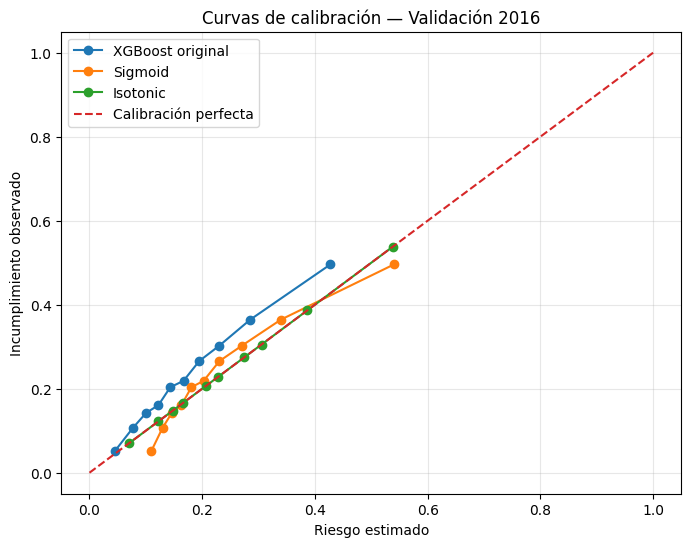

In [82]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

plt.figure(figsize=(8, 6))

for nombre, proba in probabilidades_modelos.items():
    observado, estimado = calibration_curve(
        y_valid,
        proba,
        n_bins=10,
        strategy="quantile"
    )

    plt.plot(estimado, observado, marker="o", label=nombre)

plt.plot([0, 1], [0, 1], linestyle="--", label="Calibración perfecta")
plt.xlabel("Riesgo estimado")
plt.ylabel("Incumplimiento observado")
plt.title("Curvas de calibración — Validación 2016")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

La grafica hace un contrast entre el porcentaje de riesgo estrimado con el inclumiento observado. Podemos ver que el ajuste Isotonic es el que sigue más congruencia la linea roja punteada que sería "calibración perfecta", sin embargo, los calibradores fueron ajustados utilizando las mismas observaciones de 2016 sobre las que se construyó esta gráfica. Por tanto, esta comparación es descriptiva y no constituye una evaluación independiente de la calibración.

Para valorar su comportamiento fuera de muestra, se comparan también los resultados obtenidos en 2017, prestando especial atención al Brier Score y a Average Precision.

### Evaluacion Final-2017
Ahora evaluaremos los 3 modelos con los valores de prueba, es decir los de 2017

In [83]:
resultados_test = []

modelos_finales = {
    "XGBoost original": xgb_model,
    "Sigmoid": modelos_calibrados["sigmoid"],
    "Isotonic": modelos_calibrados["isotonic"]
}

for nombre, modelo in modelos_finales.items():
    proba = modelo.predict_proba(X_test)[:, 1]

    resultados_test.append({
        "modelo": nombre,
        "ROC-AUC": roc_auc_score(y_test, proba),
        "Average Precision": average_precision_score(y_test, proba),
        "Brier Score": brier_score_loss(y_test, proba)
    })

print(
    pd.DataFrame(resultados_test)
    .round(4)
    .to_string(index=False)
)

          modelo  ROC-AUC  Average Precision  Brier Score
XGBoost original   0.6863             0.3878       0.1691
         Sigmoid   0.6863             0.3878       0.1674
        Isotonic   0.6862             0.3816       0.1658


La conclusión es bastante clara: la calibración mejora las probabilidades, pero no mejora la capacidad de discriminación del modelo. La decisión final depende del objetivo: si priorizamos probabilidades fiables, Isotonic, si se prefiere una transformación más sencilla y estable, Sigmoid.

## Evlauacion del umbral sobre el conjunto de prueba

Bien, ya sabemos que XGBoost discrima entre créditos con diferente riesgo y que la calibración mejora ligeramente sus probabilidades, pero falta responder una pregunta importasnte: **¿Qué ocurre cuando convertimos esas probabilidades en decisiones?**

Usaremos ambas calibraciones con el umbral elegido de 0.15 para el 2017 y ver el impacto operativo que tiene usar el modelo

In [84]:
umbral = 0.15

modelos_decision = {
    "Sigmoid": modelos_calibrados["sigmoid"],
    "Isotonic": modelos_calibrados["isotonic"]
}

resultados_decision = []

for nombre, modelo in modelos_decision.items():
    probabilidades = modelo.predict_proba(X_test)[:, 1]
    predicciones = (probabilidades >= umbral).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predicciones,
        labels=[0, 1]
    ).ravel()

    resultados_decision.append({
        "modelo": nombre,
        "umbral": umbral,
        "precision": precision_score(y_test, predicciones),
        "recall": recall_score(y_test, predicciones),
        "F1": f1_score(y_test, predicciones),
        "verdaderos_positivos": tp,
        "falsos_negativos": fn,
        "falsos_positivos": fp,
        "verdaderos_negativos": tn,
        "total_alertas": tp + fp
    })

In [85]:
tabla_decisiones = pd.DataFrame(resultados_decision)

print(tabla_decisiones.round(4).to_string(index=False))

  modelo  umbral  precision  recall     F1  verdaderos_positivos  falsos_negativos  falsos_positivos  verdaderos_negativos  total_alertas
 Sigmoid    0.15     0.2903  0.8758 0.4361                  5133               728             12546                  6612          17679
Isotonic    0.15     0.2918  0.8678 0.4368                  5086               775             12343                  6815          17429


Con un umbral de 0.15, ambos modelos detectan la mayoría de los incumplimientos, pero alrededor del 71% de sus alertas son falsas. Eso podría ser costoso si cada alerta requiere una revisión manual.

Bien, es aqui donde nos hacemos la pregunta **¿Cuál elegir?** Bien, si el obejtivo es minimizar los incumplimientos que no se detectan, Sigmoid seria un mejor modelo ya que detecta 88% de los incumplimientos, pero dependiendo de la metodología que se utilice para detectar los casos, y si esta es más costosa o limitada, Isotonic podría resultar como mejor opción.

# Conclusiones

XGBoost obtuvo el mayor ROC-AUC en la validación de 2016 (0.7), con un F1 de 0.45 al utilizar un umbral de 0.15. En la evaluación de 2017, el ROC-AUC fue de 0.69, lo que refleja una capacidad de discriminación moderada y una disminución respecto al periodo de validación. La calibración mejoró modestamente el Brier Score en la prueba de 2017: de 0.1691 con XGBoost original a 0.1674 con sigmoid y 0.1658 con isotonic. Isotonic obtuvo el menor Brier Score, mientras que sigmoid conservó un Average Precision ligeramente superior. Por tanto, no existe un ganador absoluto en todas las métricas.

Con un umbral de 0.15, ambos métodos calibrados detectaron una proporción elevada de los incumplimientos de 2017, aunque generaron un volumen considerable de falsas alertas. Esto evidencia la necesidad de considerar los costos de los falsos positivos y falsos negativos antes de seleccionar un umbral operativo.

En conjunto, los resultados muestran que XGBoost identifica cierta señal predictiva, pero su capacidad de discriminación es limitada y la mejora de calibración es modesta.